In [8]:
import os
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from feat import Detector

In [13]:
# Constants
VIDEO_FOLDER = 'data/videos'
DATA_FILE = 'data/excel.xlsx'
N_FRAMES = 30  # Number of frames to sample from each video

# Load data
data = pd.read_excel(DATA_FILE)

100%|██████████| 30/30 [00:14<00:00,  2.00it/s]
  batch_output = pd.concat(batch_output)



Error processing UGQ5W4.joke2.rep3.take1.ThatsNotAHat.mp4: "None of [Index(['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r',\n       'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r',\n       'AU25_r', 'AU26_r', 'AU45_r'],\n      dtype='object')] are in the [index]"


100%|██████████| 30/30 [00:24<00:00,  1.25it/s]


Error processing AQBE7J.joke1.rep3.take1.Peekaboo.mp4: "None of [Index(['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r',\n       'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r',\n       'AU25_r', 'AU26_r', 'AU45_r'],\n      dtype='object')] are in the [index]"


100%|██████████| 30/30 [00:23<00:00,  1.25it/s]
  batch_output = pd.concat(batch_output)



Error processing ZCH3UU.joke1.rep1.take1.TearingPaper.mp4: "None of [Index(['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r',\n       'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r',\n       'AU25_r', 'AU26_r', 'AU45_r'],\n      dtype='object')] are in the [index]"


... (2,840 outputs left out)

100%|██████████| 30/30 [00:26<00:00,  1.13it/s]


Error processing PCWJGR.joke1.rep2.take1.ThatsNotAHat.mp4: "None of [Index(['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r',\n       'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r',\n       'AU25_r', 'AU26_r', 'AU45_r'],\n      dtype='object')] are in the [index]"


100%|██████████| 30/30 [00:18<00:00,  1.61it/s]
  batch_output = pd.concat(batch_output)

  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Processed 4JDccE.joke4.rep3.take1.ThatsNotACat.mp4: Combined feature shape: (34,)
Final features array shape: (286, 34)
Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3064 - loss: 1.6047 - val_accuracy: 0.3553 - val_loss: 1.5900
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 763us/step - accuracy: 0.3991 - loss: 1.5857 - val_accuracy: 0.3553 - val_loss: 1.5712
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 755us/step - accuracy: 0.3982 - loss: 1.5673 - val_accuracy: 0.3553 - val_loss: 1.5537
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 721us/step - accuracy: 0.3681 - loss: 1.5546 - val_accuracy: 0.3553 - val_loss: 1.5371
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 684us/step - accuracy: 0.3898 - loss: 1.5351 - val_accuracy: 0.3553 - val_loss: 1.5213
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - accuracy: 0.4040 - loss: 1.5164 - val_accuracy: 0.3553 - val_loss: 1.5061
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 651us/step - accuracy: 0.3998 - loss: 1.5041 - val_accuracy: 0.3553 - val

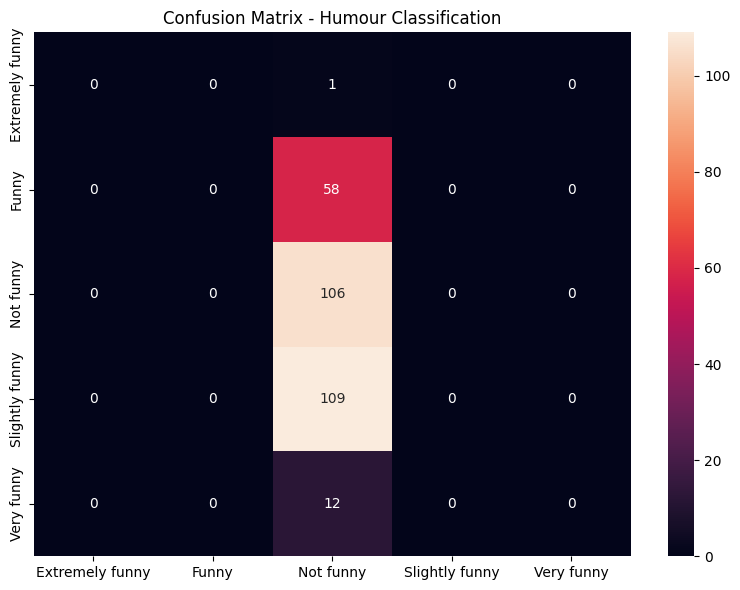

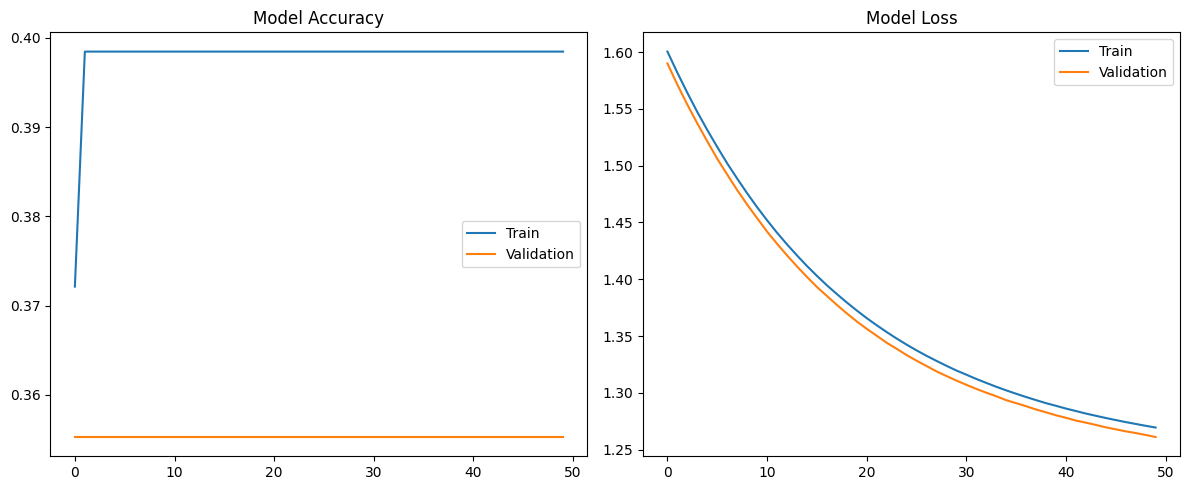

In [15]:
# Initialize the py-feat detector
detector = Detector()

# Feature extraction functions
def sample_frames(video_path, n_frames):
    cap = cv2.VideoCapture(video_path)
    frames = []
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for i in range(n_frames):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_count * i / n_frames))
        ret, frame = cap.read()
        if ret:
            frame = cv2.resize(frame, (224, 224))
            frames.append(frame)
    cap.release()
    return np.array(frames)

def extract_facial_features_pyfeat(video_path, n_frames):
    frames = sample_frames(video_path, n_frames)
    frame_paths = []
    for i, frame in enumerate(frames):
        frame_path = f"temp_frame_{i}.jpg"
        cv2.imwrite(frame_path, frame)
        frame_paths.append(frame_path)
    
    # Use py-feat to extract features
    faces = detector.detect_image(frame_paths)
    for frame_path in frame_paths:
        os.remove(frame_path)  # Clean up temporary frame files
    
    # Aggregate features for two faces
    facial_features = []
    for i in range(n_frames):
        frame_faces = faces[faces['frame'] == i]
        if len(frame_faces) >= 2:
            face1_features = frame_faces.iloc[0][['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r', 'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r', 'AU25_r', 'AU26_r', 'AU45_r']].values
            face2_features = frame_faces.iloc[1][['AU01_r', 'AU02_r', 'AU04_r', 'AU05_r', 'AU06_r', 'AU07_r', 'AU09_r', 'AU10_r', 'AU12_r', 'AU14_r', 'AU15_r', 'AU17_r', 'AU20_r', 'AU23_r', 'AU25_r', 'AU26_r', 'AU45_r']].values
            combined_features = np.concatenate([face1_features, face2_features])
            facial_features.append(combined_features)
        else:
            # If less than 2 faces detected, append zeros
            facial_features.append(np.zeros(34))
    
    return np.mean(facial_features, axis=0)

# Custom transformer for feature extraction
class VideoFeatureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.scaler = StandardScaler()
    
    def fit(self, X, y=None):
        return self
    
    def transform(self, X):
        features = []
        for video_file in X:
            video_path = os.path.join(VIDEO_FOLDER, video_file)
            if not os.path.exists(video_path):
                print(f"Video file not found: {video_path}")
                continue
            
            try:
                facial_feat = extract_facial_features_pyfeat(video_path, N_FRAMES)
                
                # Ensure all features have consistent shapes
                facial_feat = np.resize(facial_feat, (34,))
                
                combined_feat = facial_feat
                features.append(combined_feat)
                
                print(f"Processed {video_file}: Combined feature shape: {combined_feat.shape}")
            except Exception as e:
                print(f"Error processing {video_file}: {str(e)}")
                # Append zero arrays if processing fails
                features.append(np.zeros(34))
        
        if not features:
            raise ValueError("No valid features extracted from videos")
        
        features_array = np.array(features)
        print(f"Final features array shape: {features_array.shape}")
        
        # Check for NaN or infinite values
        if np.isnan(features_array).any():
            print("Warning: NaN values detected in features")
            features_array = np.nan_to_num(features_array)
        if np.isinf(features_array).any():
            print("Warning: Infinite values detected in features")
            features_array = np.nan_to_num(features_array)
        
        scaled_features = self.scaler.fit_transform(features_array)
        
        return scaled_features

# Prepare data
X = data['VideoID']
y = data['HowFunny']

# Handle missing values
imputer = SimpleImputer(strategy='most_frequent')
y = imputer.fit_transform(y.values.reshape(-1, 1)).ravel()

# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

# Feature extraction pipeline
feature_pipeline = Pipeline([
    ('feature_extractor', VideoFeatureExtractor()),
])

X_train_features = feature_pipeline.fit_transform(X_train)
X_test_features = feature_pipeline.transform(X_test)

# Build and train the model
input_shape = X_train_features.shape[1]
num_classes = len(le.classes_)

model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(input_shape,)))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    X_train_features, 
    y_train, 
    epochs=50, 
    batch_size=32, 
    validation_split=0.2,
    verbose=1
)

# Evaluate performance
y_pred = model.predict(X_test_features)
y_pred = np.argmax(y_pred, axis=1)

print("Humour Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - Humour Classification')
plt.tight_layout()
plt.show()

# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.legend()
plt.subplot(122)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.legend()
plt.tight_layout()
plt.show()